# 09｜網格資料與地形：坡度要在公尺下算

**115-1 地理資訊系統運用程式｜W9（11/12）**

W6、W7 的資料是**向量**：站點、車站、行政界，每一筆都有自己的座標。這週換成**網格**：一張二維陣列，每一格存一個數值（高程），位置由「左上角座標＋格子大小」決定。

今天的問題：**YouBike 站點在平地還是坡地？** 先把每個站點的**高程**與**坡度**算對；W10 再和即時的可借車數放在一起看。

> **這週的錯誤都不會報錯。** 坡度單位錯了、CRS 沒對齊、nodata 沒遮罩，程式照樣跑完，數字也「看起來像」坡度或高程。抓錯靠的是常識檢查。

| Part | 內容 |
|---|---|
| A | GeoTIFF 的說明書：CRS、解析度、範圍、nodata、transform |
| B | rioxarray：nodata 遮罩、裁切到臺中市 |
| C | 坡度：網格大小的單位、常識檢查、agent 常見的兩種錯誤、nodata 與邊界 |
| D | 在站點取樣：CRS 對齊、驗證、單點與周圍平均 |
| E | 地圖：暈渲圖、坡度分級、各區比較、`explore()` |
| F | 解析度：20 公尺看得到什麼？存檔給 HW10 |

**課前準備：** 從老師分享的雲端資料夾 `dem20m_2026` 下載 `dem20m_Taichung.tif`（和你 HW9 縣市的檔案），上傳到 `115-1_GISprog/data/raw/dem20m_2026/`。W6 的 `Taiwan_boundaries`、`tdx_station_20261012` 沿用。**本週不呼叫 TDX API。**

## 0. 安裝套件、路徑與中文字型

Colab 沒有預裝 `rioxarray`；`mapclassify` 是 E4 的 `explore()` 要用的。裝完不必重新啟動。

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/115-1_GISprog")
    %pip install -q rioxarray mapclassify
else:
    # 備援：本機執行時，notebook 位於 115-1_GISprog/notebooks/，上一層就是專案資料夾
    PROJECT_DIR = Path.cwd().parent

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FONT_DIR = PROJECT_DIR / "fonts"

DEM_TIF = RAW_DIR / "dem20m_2026" / "dem20m_Taichung.tif"             # 內政部 20 m DEM（臺中市）
TOWN_SHP = RAW_DIR / "Taiwan_boundaries" / "Town" / "Taiwan_town.shp"  # 鄉鎮市區界
BIKE_BACKUP = RAW_DIR / "tdx_station_20261012"                         # W6 站點備援快照

for p in [DEM_TIF, TOWN_SHP, BIKE_BACKUP]:
    if not p.exists():
        raise FileNotFoundError(f"找不到 {p}，請依課前準備上傳")

print("執行環境：", "Google Colab" if IN_COLAB else "本機")

執行環境： 本機


In [2]:
import urllib.request

import matplotlib.pyplot as plt
from matplotlib import font_manager

FONT_URL = "https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download"
FONT_PATH = FONT_DIR / "TaipeiSansTCBeta-Regular.ttf"

if not FONT_PATH.exists():
    FONT_DIR.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(FONT_URL, FONT_PATH)

font_manager.fontManager.addfont(str(FONT_PATH))     # 告訴 Matplotlib：「這個字型檔可以使用」
plt.rcParams["font.family"] = "Taipei Sans TC Beta"  # 指定之後畫圖預設使用這個中文字型
plt.rcParams["axes.unicode_minus"] = False           # 避免負號 − 顯示異常
print("已設定中文字型：", FONT_PATH.name)

已設定中文字型： TaipeiSansTCBeta-Regular.ttf


---

# Part A｜GeoTIFF 的說明書

## A1. 先讀檔頭，不讀資料

`rasterio.open()` 只讀檔案開頭的「說明書」（中繼資料），還沒有把任何一格讀進記憶體。

In [3]:
import numpy as np
import rasterio

src = rasterio.open(DEM_TIF)
print("CRS     ：", src.crs, "｜單位：", src.crs.linear_units)
print("列 × 欄 ：", src.height, "×", src.width, f"（共 {src.height * src.width:,} 格）")
print("解析度  ：", src.res)
print("範圍    ：", src.bounds)
print("nodata  ：", src.nodata, "｜資料型態：", src.dtypes[0])

CRS     ： EPSG:3826 ｜單位： metre
列 × 欄 ： 2555 × 5154 （共 13,168,470 格）
解析度  ： (20.0, 20.0)
範圍    ： BoundingBox(left=193790.0, bottom=2653870.0, right=296870.0, top=2704970.0)
nodata  ： -32767.0 ｜資料型態： float32


- **解析度的單位 = CRS 的單位**：EPSG:3826 的單位是公尺，所以一格是 20 × 20 公尺。這週的錯誤都從這裡開始。
- **nodata**：海面與原始資料範圍外的格子，用一個特別的數字（−32767）代表。
- 約 1,317 萬格 × 4 bytes（float32）≈ 53 MB：整張讀進記憶體沒問題，但算坡度時會多出好幾份同樣大小的陣列，用完的要 `del`。

## A2. transform：第幾列第幾欄 ↔ 座標

`transform` 記錄左上角的座標與格子大小。有了它，就能從座標找到格子、讀出那一格的數值。下面用 W7 的臺鐵臺中站（TDX 車站資料的經緯度）。

In [4]:
import geopandas as gpd
from rasterio.windows import Window

print(src.transform)

臺中站 = gpd.GeoSeries(gpd.points_from_xy([120.68691], [24.13728]), crs="EPSG:4326").to_crs(src.crs)
x0, y0 = 臺中站.x[0], 臺中站.y[0]
列, 欄 = src.index(x0, y0)
print(f"臺鐵臺中站：x = {x0:.1f}、y = {y0:.1f} → 第 {列} 列、第 {欄} 欄")
print(src.read(1, window=Window(欄 - 1, 列 - 1, 3, 3)))   # 周圍 3 × 3 格的高程，中間那格就是車站

c:\Users\s1112\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\s1112\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


| 20.00, 0.00, 193790.00|
| 0.00,-20.00, 2704970.00|
| 0.00, 0.00, 1.00|
臺鐵臺中站：x = 218179.5、y = 2670262.2 → 第 1735 列、第 1219 欄
[[75.93 75.84 75.71]
 [76.02 75.97 75.95]
 [75.83 75.94 76.15]]


- transform 第一列：往右一欄，x **加** 20 公尺；第二列：往下一列，y **減** 20 公尺。第 0 列在最北邊，所以 y 的格子大小是負的。
- 「用座標找格子、讀出數值」就是**取樣**，Part D 會一次對全部站點做。

**【練習 A】** `src.xy(列, 欄)` 回傳那一格**中心**的座標。第 0 列第 0 欄的中心，和 `src.bounds` 的左邊界、上邊界各差多少公尺？為什麼？

In [ ]:
# TODO：印出 src.xy(0, 0)，和 src.bounds.left、src.bounds.top 相減
print("左邊界相差：", src.xy(0, 0)[0] - src.bounds.left)
print("上邊界相差：", src.xy(0, 0)[1] - src.bounds.top)

---

# Part B｜rioxarray：nodata 與裁切

`rioxarray` 把 GeoTIFF 讀成 xarray 的 `DataArray`：像 NumPy 陣列，但每一格都帶著 x、y 座標，而且多了 `.rio`，可以裁切、重新投影。

## B1. 不告訴程式哪個是 nodata

In [6]:
import rioxarray
import xarray as xr

原始 = rioxarray.open_rasterio(DEM_TIF).squeeze("band", drop=True)   # 只有一個波段，拿掉 band 這一維
print(原始.shape, 原始.dtype)
print("最低：", float(原始.min()), "｜最高：", round(float(原始.max()), 2))

(2555, 5154) float32
最低： -32767.0 ｜最高： 3883.63


臺中市最低的地方是 −32,767 公尺？這就是 A1 的 `nodata`。沒有告訴程式，它只是一個普通的數字，`min`、`mean` 照算。

## B2. `masked=True`：nodata 換成 NaN

In [7]:
dem = rioxarray.open_rasterio(DEM_TIF, masked=True).squeeze("band", drop=True)
print("最低：", round(float(dem.min()), 2), "｜最高：", round(float(dem.max()), 2))
print("NaN（原本是 nodata）的格子：", f"{int(dem.isnull().sum()):,}", "格")
print("CRS：", dem.rio.crs, "｜網格大小：", dem.rio.resolution())

最低： -5.42 ｜最高： 3883.63
NaN（原本是 nodata）的格子： 643,068 格
CRS： EPSG:3826 ｜網格大小： (20.0, -20.0)


- `masked=True` 之後，nodata 變成 **NaN**，`min`、`mean`、`median` 會跳過它。
- 常識檢查：雪山主峰 3,886 公尺，最高的格子 3,883.6 公尺，合理。最低 −5.42 公尺在清水區的海邊，沿海低窪地略低於海平面，也說得通。
- `rio.resolution()` 的 y 是負的，原因同 A2；算坡度時取絕對值。

**【練習 B】** 沒加 `masked=True` 時，整張 DEM 的平均高程是多少？加了之後呢？nodata 占了幾 % 的格子？

In [8]:
# TODO：比較 原始.mean() 與 dem.mean()；nodata 的比例可以用 (原始 == src.nodata).mean()

## B3. `rio.clip`：裁切到臺中市

`crs=` 告訴 rioxarray 多邊形的 CRS，和 DEM 不同時會自動轉換。鄉鎮界本來就是 EPSG:3826，這裡只是養成習慣。

c:\Users\s1112\anaconda3\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


裁切前： (2555, 5154) → 裁切後： (2453, 5053)


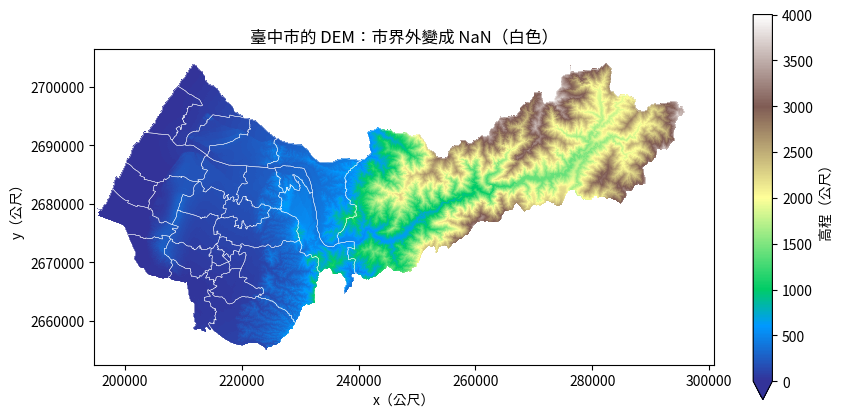

In [9]:
town = gpd.read_file(TOWN_SHP)
臺中 = town[town["COUNTYNAME"] == "臺中市"]
dem_臺中 = dem.rio.clip(臺中.geometry, crs=臺中.crs)
print("裁切前：", dem.shape, "→ 裁切後：", dem_臺中.shape)

fig, ax = plt.subplots(figsize=(10, 5))
dem_臺中.plot.imshow(ax=ax, cmap="terrain", vmin=0, vmax=4000, cbar_kwargs={"label": "高程（公尺）"})
臺中.boundary.plot(ax=ax, color="white", linewidth=0.3)
ax.set_title("臺中市的 DEM：市界外變成 NaN（白色）")
ax.set(xlabel="x（公尺）", ylabel="y（公尺）", aspect="equal")
ax.ticklabel_format(style="plain")
plt.show()

---

# Part C｜坡度：分母的單位決定一切

## C1. 用 `np.gradient` 算坡度

$$\text{坡度} = \arctan\sqrt{\left(\frac{\partial z}{\partial x}\right)^2 + \left(\frac{\partial z}{\partial y}\right)^2}$$

`np.gradient` 算出每一格的「高差 ÷ 距離」。高差是公尺，**距離也必須是公尺**。

**先在整張 DEM 上算，再裁切或取樣**：邊界的格子才有鄰居（C6）。

In [10]:
格網 = abs(dem.rio.resolution()[0])
print("網格大小：", 格網, dem.rio.crs.linear_units)

dz_dy, dz_dx = np.gradient(dem.values, 格網)    # 第 0 軸南北、第 1 軸東西
坡度 = dem.copy(data=np.degrees(np.arctan(np.hypot(dz_dx, dz_dy))))
del dz_dy, dz_dx                                 # 中間結果用完就刪，Colab 記憶體比較寬裕
print("坡度：", round(float(坡度.min()), 2), "～", round(float(坡度.max()), 2), "度")

網格大小： 20.0 metre
坡度： 0.0 ～ 83.16 度


## C2. 度與百分比

道路與自行車道常用**百分比**：水平 100 公尺上升幾公尺。換算是 `tan`，不是固定倍數。

In [11]:
import pandas as pd

pd.set_option("display.precision", 2)   # 表格顯示到小數 2 位（DEM 是 float32，不設定會顯示成 24.700001）

度 = np.array([1, 2, 3, 5, 10, 30, 45])
pd.DataFrame({"度": 度, "百分比": (np.tan(np.radians(度)) * 100).round(1)})

,度,百分比
0,1,1.7
1,2,3.5
2,3,5.2
3,5,8.7
4,10,17.6
5,30,57.7
6,45,100.0


5 度約 8.7%，騎腳踏車已經很吃力。筆記只寫「坡度 5」不寫單位，讀的人不知道是哪一種。

## C3. 常識檢查：市區應該接近 0 度

先猜：中區、西屯區、和平區的坡度中位數大約幾度？寫下來再執行。

In [12]:
def 各區中位數(陣列, 區名):
    """把 陣列 裁切到每一個區，回傳各區的中位數。"""
    return [float(陣列.rio.clip(臺中[臺中["TOWNNAME"] == 區].geometry, crs=臺中.crs).median()) for 區 in 區名]


區名 = ["中區", "西區", "北區", "西屯區", "北屯區", "和平區"]
常識 = pd.DataFrame({"區": 區名, "高程中位數_m": 各區中位數(dem, 區名), "坡度中位數_度": 各區中位數(坡度, 區名)}).round(1)
常識

,區,高程中位數_m,坡度中位數_度
0,中區,77.6,0.8
1,西區,74.3,0.8
2,北區,97.1,0.8
3,西屯區,107.2,1.4
4,北屯區,216.8,7.7
5,和平區,1982.0,37.3


中區、西區、北區在臺中盆地；西屯區西半部在大肚山台地；北屯區有大坑丘陵；和平區是山區。**和你對臺中的印象相符，才繼續往下做。** 這就是 HW9 ★ 決策點 2 的驗證方式。

## C4. agent 常見的錯誤一：沒給網格大小

`np.gradient` 沒給第二個參數時，預設相鄰兩格的距離是 **1**。

In [13]:
dy, dx = np.gradient(dem.values)                # 沒給網格大小
錯的坡度 = dem.copy(data=np.degrees(np.arctan(np.hypot(dx, dy))))
del dy, dx
常識["沒給網格大小_度"] = np.round(各區中位數(錯的坡度, 區名), 1)
常識

,區,高程中位數_m,坡度中位數_度,沒給網格大小_度
0,中區,77.6,0.8,15.9
1,西區,74.3,0.8,15.2
2,北區,97.1,0.8,16.2
3,西屯區,107.2,1.4,26.7
4,北屯區,216.8,7.7,69.8
5,和平區,1982.0,37.3,86.2


中區從 0.8 度變成 15.9 度：高差除以 1 而不是 20，坡度被放大。**沒有報錯**，數字也「看起來像坡度」。如果沒有先做 C3，你看得出來嗎？

## C5. agent 常見的錯誤二：經緯度的 DEM

請 agent「把臺中市的 DEM 轉成 WGS84 再算坡度」，它常直接把 `rio.resolution()` 當成 `np.gradient` 的間距，這時網格大小的單位是**度**。為了快一點，只取舊市區的 5 個區。

EPSG:4326 的網格大小： 0.00018817237391070482 -0.00018817237391070482 （單位：度）
舊市區的坡度中位數：EPSG:3826 0.8 度；EPSG:4326 90.0 度


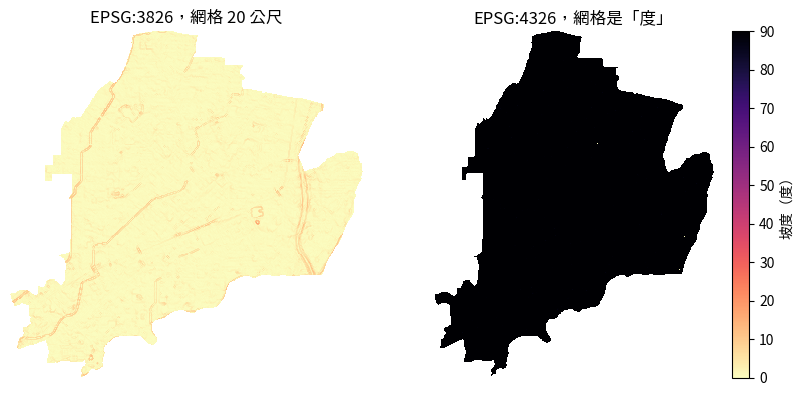

In [14]:
市區 = 臺中[臺中["TOWNNAME"].isin(["中區", "東區", "南區", "西區", "北區"])]
dem_市區 = dem.rio.clip(市區.geometry, crs=市區.crs)
dem_經緯度 = dem_市區.rio.reproject("EPSG:4326")
格網x, 格網y = dem_經緯度.rio.resolution()
print("EPSG:4326 的網格大小：", 格網x, 格網y, "（單位：度）")

dy, dx = np.gradient(dem_經緯度.values, abs(格網y), abs(格網x))
坡度_經緯度 = dem_經緯度.copy(data=np.degrees(np.arctan(np.hypot(dx, dy))))
坡度_市區 = 坡度.rio.clip(市區.geometry, crs=市區.crs)
print("舊市區的坡度中位數：EPSG:3826", round(float(坡度_市區.median()), 1), "度；EPSG:4326",
      round(float(坡度_經緯度.median()), 1), "度")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
坡度_市區.plot.imshow(ax=axes[0], cmap="magma_r", vmin=0, vmax=90, add_colorbar=False)
坡度_經緯度.plot.imshow(ax=axes[1], cmap="magma_r", vmin=0, vmax=90, cbar_kwargs={"label": "坡度（度）"})
axes[0].set_title("EPSG:3826，網格 20 公尺")
axes[1].set_title("EPSG:4326，網格是「度」")
for ax in axes:
    ax.set_axis_off()
plt.show()

高差是公尺、距離是 0.000188「度」：分母小了約 11 萬倍，整個舊市區接近 90 度。修正方式有兩種：在 EPSG:3826 下算（本課程的做法），或把度換成公尺（經度還要乘 cos(緯度)，比較麻煩）。

## C6. nodata 與邊界

坡度用到**相鄰的格子**：一格是 nodata，旁邊的格子也跟著出錯。

In [15]:
dy, dx = np.gradient(原始.values, 格網)                              # 沒遮罩 nodata
沒遮罩 = np.degrees(np.arctan(np.hypot(dx, dy)))
print("坡度超過 80 度的格子：遮罩後", int((坡度 > 80).sum()), "格；沒遮罩", int((沒遮罩 > 80).sum()), "格")

dy, dx = np.gradient(dem_臺中.values, 格網)                          # 先裁切再算坡度
先裁再算 = np.degrees(np.arctan(np.hypot(dx, dy)))
先算再裁 = 坡度.rio.clip(臺中.geometry, crs=臺中.crs)
有高程 = dem_臺中.notnull().values
print("臺中市範圍內坡度是 NaN 的格子：先裁再算", int((有高程 & np.isnan(先裁再算)).sum()),
      "格；先算再裁", int((有高程 & 先算再裁.isnull().values).sum()), "格")
del dy, dx, 沒遮罩, 先裁再算, 錯的坡度

坡度超過 80 度的格子：遮罩後 106 格；沒遮罩 6511 格
臺中市範圍內坡度是 NaN 的格子：先裁再算 15022 格；先算再裁 463 格


- 沒遮罩時多出來的「懸崖」都緊鄰 nodata，大多在海岸線上：陸地旁邊的格子是 −32767。
- 先裁再算：市界旁的格子少了鄰居，坡度變成 NaN，市界附近的站點就取不到坡度。

> **順序：遮罩 nodata → 算坡度 → 裁切或取樣。**

**【練習 C】** 把坡度換成百分比，C3 的 6 個區各是幾 %？臺中市範圍內（`先算再裁`），坡度超過 5 度（約 8.7%）的格子占幾 %？

In [16]:
# TODO：百分比 = np.tan(np.radians(坡度.values)) * 100，用 坡度.copy(data=...) 包回 DataArray 再用 各區中位數()

---

# Part D｜在站點取樣

## D1. 讀站點，轉成 DEM 的 CRS

課堂用 W6 的臺中市站點備援快照（10/12）。**HW9 改讀你自己存在 `data/raw/tdx/` 的快照。**

In [17]:
import json


def 讀站點(代碼):
    """讀 W6 的站點備援快照，回傳 GeoDataFrame（EPSG:4326）。HW9：改讀你自己的快照。"""
    df = pd.json_normalize(json.loads((BIKE_BACKUP / f"station_{代碼}.json").read_text(encoding="utf-8")))
    df = df.rename(columns={"StationName.Zh_tw": "站點名稱"})
    return gpd.GeoDataFrame(
        df[["StationUID", "StationID", "站點名稱"]],
        geometry=gpd.points_from_xy(df["StationPosition.PositionLon"], df["StationPosition.PositionLat"]),
        crs="EPSG:4326",
    )


站點_經緯度 = 讀站點("Taichung")
站點 = 站點_經緯度.to_crs(dem.rio.crs)      # 先轉成 DEM 的 CRS
print(len(站點), "站；站點 EPSG:", 站點.crs.to_epsg(), "｜DEM EPSG:", dem.rio.crs.to_epsg())

1838 站；站點 EPSG: 3826 ｜DEM EPSG: 3826


## D2. 一次取樣全部站點

x、y 各包成 `DataArray`，**用同一個維度名稱**，`sel` 才會一對一配對。

In [18]:
x = xr.DataArray(站點.geometry.x.values, dims="站點")
y = xr.DataArray(站點.geometry.y.values, dims="站點")
站點["高程_m"] = dem.sel(x=x, y=y, method="nearest").values
站點["坡度_度"] = 坡度.sel(x=x, y=y, method="nearest").values
print("取到", len(站點), "個值；高程是 NaN 的站：", 站點["高程_m"].isna().sum(), "；坡度是 NaN 的站：", 站點["坡度_度"].isna().sum())

交叉 = dem.sel(x=站點.geometry.x.values, y=站點.geometry.y.values, method="nearest")
print("直接傳 list：", 交叉.shape, "← x 和 y 交叉組合，不是一對一")
del 交叉
站點[["站點名稱", "高程_m", "坡度_度"]].head()

取到 1838 個值；高程是 NaN 的站： 0 ；坡度是 NaN 的站： 0
直接傳 list： (1838, 1838) ← x 和 y 交叉組合，不是一對一


,站點名稱,高程_m,坡度_度
0,YouBike2.0_綠川東中山路口,74.32,0.32
1,YouBike2.0_繼光光復路口,76.72,1.08
2,YouBike2.0_柳原教會,82.73,0.97
3,YouBike2.0_臺中車站(建國路),74.99,0.76
4,YouBike2.0_柳川東中華路口,82.80,0.84


## D3. agent 常見的錯誤三：拿經緯度去取樣

In [19]:
錯 = dem.sel(x=xr.DataArray(站點_經緯度.geometry.x.values, dims="站點"),
             y=xr.DataArray(站點_經緯度.geometry.y.values, dims="站點"), method="nearest")
print("取到的格子 x：", np.unique(錯.x.values), "｜y：", np.unique(錯.y.values))
print("DEM 最左下角那一格：", float(dem.x.min()), float(dem.y.min()))
print("取到的高程：", np.unique(錯.values))

取到的格子 x： [193800.] ｜y： [2653880.]
DEM 最左下角那一格： 193800.0 2653880.0
取到的高程： [9.22]


經度 120.7 離 TWD97 的 x（20 萬左右）太遠，「最近的格子」永遠是**最左下角**。臺中市 DEM 的左下角在彰化縣埔鹽鄉的陸地上，所以全部站點都取到同一個值：看起來是合理的高程，**也沒有報錯**。如果你的縣市 DEM 左下角是海，就會是一整欄 NaN。

> ★ 決策點「CRS 對齊」：印出兩者的 EPSG，再檢查取樣結果。

## D4. 驗證取樣結果

1. **換一種方法取同一個值：** `src.sample()` 是 rasterio 的函式，和 xarray 的 `sel` 是不同的程式。
2. **用常識：** 海邊 → 盆地 → 台地。

In [20]:
前5站 = 站點.head(5)
用sample = [v[0] for v in src.sample(zip(前5站.geometry.x, 前5站.geometry.y))]
print("src.sample：", np.round(用sample, 2))
print("sel       ：", 前5站["高程_m"].round(2).values)

地標 = ["YouBike2.0_高美濕地第二停車場", "YouBike2.0_臺中車站(建國路)", "YouBike2.0_東海大學_路思義教堂"]
站點.set_index("站點名稱").loc[地標, ["高程_m", "坡度_度"]].round(2)

src.sample： [74.32 76.72 82.73 74.99 82.8 ]
sel       ： [74.32 76.72 82.73 74.99 82.8 ]


,高程_m,坡度_度
站點名稱,,
YouBike2.0_高美濕地第二停車場,5.00,0.51
YouBike2.0_臺中車站(建國路),74.99,0.76
YouBike2.0_東海大學_路思義教堂,178.02,3.67


高美濕地在海邊，臺中車站在臺中盆地，東海大學在大肚山台地上。HW9 要挑 2–3 個你熟悉的站點做同樣的檢查。

## D5. 單點，還是周圍平均？

站點旁邊剛好有一段邊坡或堤防，單點的坡度就會很大。取站點周圍 5 × 5 格（約 100 × 100 公尺）的平均來比較：只在站點附近取 25 個值，**不必對整張 DEM 做 `rolling`**，Colab 記憶體比較安全。

In [21]:
偏移 = [-40, -20, 0, 20, 40]                     # 周圍 5 × 5 格，約 100 × 100 公尺
周圍 = [坡度.sel(x=x + dx, y=y + dy, method="nearest").values for dx in 偏移 for dy in 偏移]
站點["坡度_周圍平均"] = np.nanmean(周圍, axis=0)
站點["單點減周圍"] = 站點["坡度_度"] - 站點["坡度_周圍平均"]

欄 = ["站點名稱", "坡度_度", "坡度_周圍平均", "單點減周圍"]
print("單點比周圍大最多：")
display(站點.nlargest(3, "單點減周圍")[欄].round(2))
print("單點比周圍小最多：")
display(站點.nsmallest(3, "單點減周圍")[欄].round(2))

單點比周圍大最多：


,站點名稱,坡度_度,坡度_周圍平均,單點減周圍
793,YouBike2.0_中臺科技大學(東北側),24.39,14.79,9.60
153,YouBike2.0_綠空廊道(林森路),12.20,5.24,6.96
1073,YouBike2.0_立仁路公教街209巷口,11.97,5.01,6.96


單點比周圍小最多：


,站點名稱,坡度_度,坡度_周圍平均,單點減周圍
1736,YouBike2.0_新田登山步道(廁所),3.99,26.21,-22.23
888,YouBike2.0_東山竹坑巷口,1.88,13.97,-12.09
1796,YouBike2.0_外埔三清總道院,2.93,11.17,-8.24


- **單點大、周圍小：** 站點旁邊剛好有一段邊坡、堤防或渠道。
- **兩者都大：** 真的在坡地上。
- **單點小、周圍大：** 站點本身在平地（例如登山口），周圍是山坡。

差最多的站，用 E4 的地圖放大看旁邊是什麼。

**【練習 D】** 單點坡度最大的 5 站是哪些？它們的周圍平均是多少？高程最高的 3 站呢？

In [22]:
# TODO：站點.nlargest(5, "坡度_度")、站點.nlargest(3, "高程_m")

---

# Part E｜地圖

## E1. 暈渲圖疊站點

`LightSource.hillshade` 模擬從西北方照下來的光，也是用 `np.gradient` 算，**`dx`、`dy` 一樣要給公尺**。只畫平地的範圍（和平區的 2 站在圖外）。

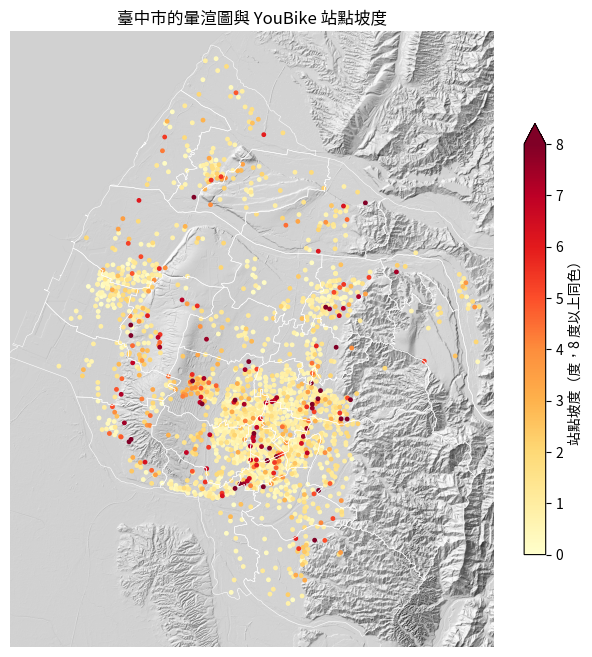

In [23]:
from matplotlib.colors import LightSource

XL, YL = (195000, 235000), (2654000, 2705000)
子 = dem.sel(x=slice(*XL), y=slice(YL[1], YL[0]))     # y 由北往南排，slice 要從大到小
暈渲 = LightSource(azdeg=315, altdeg=45).hillshade(np.nan_to_num(子.values), vert_exag=2, dx=格網, dy=格網)
範圍 = [float(子.x.min()) - 10, float(子.x.max()) + 10, float(子.y.min()) - 10, float(子.y.max()) + 10]

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(暈渲, cmap="gray", extent=範圍)
臺中.boundary.plot(ax=ax, color="white", linewidth=0.4)
排序 = 站點.sort_values("坡度_度")                       # 陡的站最後畫，才不會被蓋住
點 = ax.scatter(排序.geometry.x, 排序.geometry.y, c=排序["坡度_度"], cmap="YlOrRd", vmin=0, vmax=8, s=6)
plt.colorbar(點, ax=ax, label="站點坡度（度，8 度以上同色）", shrink=0.7, extend="max")
ax.set_xlim(*XL)
ax.set_ylim(*YL)
ax.set_title("臺中市的暈渲圖與 YouBike 站點坡度")
ax.set_axis_off()
plt.show()

## E2. 坡度分級

連續的坡度不好讀，分成幾級再畫。級距要說得出理由：這裡用騎腳踏車的感受（3 度約 5%、5 度約 8.7%）。

坡度分級
未滿 1 度：平地     932
1–3 度：緩坡      683
3–5 度：有感的坡    112
5 度以上：陡       111
Name: count, dtype: int64


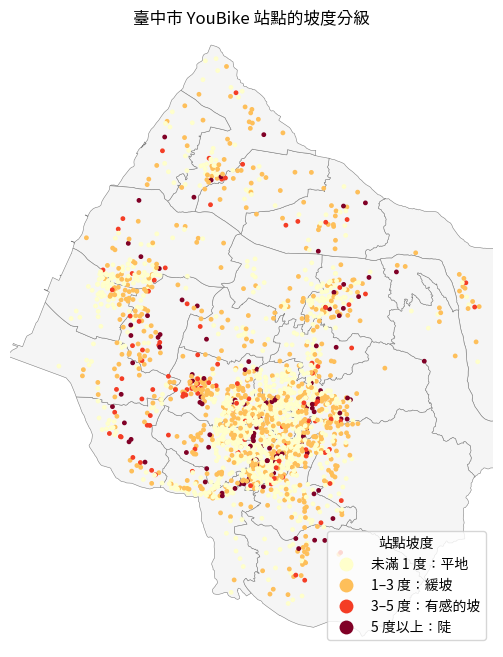

In [24]:
級距 = [0, 1, 3, 5, 90]
級名 = ["未滿 1 度：平地", "1–3 度：緩坡", "3–5 度：有感的坡", "5 度以上：陡"]
站點["坡度分級"] = pd.cut(站點["坡度_度"], bins=級距, labels=級名, right=False)
print(站點["坡度分級"].value_counts().sort_index())

fig, ax = plt.subplots(figsize=(8, 8))
臺中.plot(ax=ax, color="whitesmoke", edgecolor="gray", linewidth=0.4)
站點.plot(ax=ax, column="坡度分級", cmap="YlOrRd", markersize=6, legend=True,
          legend_kwds={"title": "站點坡度", "loc": "lower right"})
ax.set_xlim(*XL)
ax.set_ylim(*YL)
ax.set_title("臺中市 YouBike 站點的坡度分級")
ax.set_axis_off()
plt.show()

## E3. 各區站點的高程

用 `sjoin` 找出每個站點所在的鄉鎮市區（W7 學過），再分組比較。盒鬚圖只畫站點 30 個以上的區。

In [25]:
站點 = gpd.sjoin(站點, town[["TOWNNAME", "geometry"]], how="left", predicate="within").drop(columns="index_right")
站點 = 站點.rename(columns={"TOWNNAME": "鄉鎮市區"})
print(len(站點), "站；沒有配對到鄉鎮市區的站：", 站點["鄉鎮市區"].isna().sum())

各區 = (站點.groupby("鄉鎮市區")
          .agg(站數=("StationUID", "size"), 高程中位數=("高程_m", "median"), 坡度中位數=("坡度_度", "median"),
               坡度超過5度=("坡度_度", lambda s: int((s > 5).sum())))
          .query("站數 >= 30")
          .sort_values("高程中位數")
          .round(1))
各區

1838 站；沒有配對到鄉鎮市區的站： 0


,站數,高程中位數,坡度中位數,坡度超過5度
鄉鎮市區,,,,
梧棲區,61,4.3,0.6,0
清水區,88,5.6,0.9,4
龍井區,36,14.0,1.3,2
大肚區,47,24.7,1.3,5
烏日區,76,28.4,0.7,4
沙鹿區,63,41.0,1.7,8
大甲區,60,48.8,1.1,4
大里區,79,51.8,0.9,4
南區,95,53.0,0.9,9


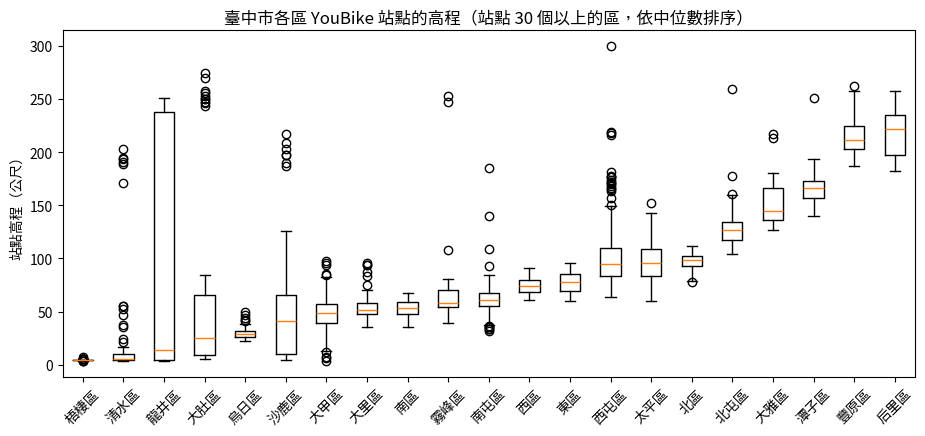

In [26]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([站點.loc[站點["鄉鎮市區"] == 區, "高程_m"] for 區 in 各區.index], tick_labels=各區.index)
ax.set_ylabel("站點高程（公尺）")
ax.set_title("臺中市各區 YouBike 站點的高程（站點 30 個以上的區，依中位數排序）")
ax.tick_params(axis="x", labelrotation=45)
plt.show()

龍井區的盒子從 5 公尺拉到 238 公尺：36 站中有 12 站在大肚山台地上（150 公尺以上），其餘在海邊的平原。大肚區、沙鹿區也各有 7–10 站在台地上（上方的圓點）。只看中位數會錯過這件事。

## E4. `explore()`：放大看站點旁邊是什麼

疊在臺灣通用電子地圖上，滑過站點看單點與周圍平均的坡度。找 D5 差最多的站，看看旁邊是堤防、渠道、高架道路還是邊坡。

In [27]:
# 臺灣通用電子地圖（內政部國土測繪中心 WMTS）；注意網址是 {z}/{y}/{x}
站點.explore(
    column="坡度_度", cmap="YlOrRd", vmin=0, vmax=8,
    tooltip=["站點名稱", "鄉鎮市區", "高程_m", "坡度_度", "坡度_周圍平均"],
    marker_kwds={"radius": 4},
    tiles="https://wmts.nlsc.gov.tw/wmts/EMAP/default/GoogleMapsCompatible/{z}/{y}/{x}",
    attr="臺灣通用電子地圖 © 內政部國土測繪中心",
)

**【練習 E】** 哪幾個區坡度超過 5 度的站最多？這些區在盆地裡，還是盆地邊緣？用 D5 的周圍平均判斷：它們真的在坡地上，還是單點取到旁邊的短坡？

In [28]:
# TODO：篩出 坡度_度 > 5 的站，groupby 鄉鎮市區，算站數、坡度_度 與 坡度_周圍平均 的中位數

---

# Part F｜解析度：20 公尺看得到什麼？

坡度用相鄰兩格（相距 40 公尺）的高差，**比 40 公尺短的坡看不到**（地下道引道、階梯）。反過來，格子變大，坡度會被**抹平**。把 DEM 每 k × k 格取平均（`coarsen`），用新的網格大小重算坡度，再取樣同一批站點：

In [29]:
解析度 = []
for k in [1, 2, 5]:
    粗 = dem if k == 1 else dem.coarsen(x=k, y=k, boundary="trim").mean()
    dy, dx = np.gradient(粗.values, 格網 * k)
    粗坡度 = 粗.copy(data=np.degrees(np.arctan(np.hypot(dx, dy))))
    s = pd.Series(粗坡度.sel(x=x, y=y, method="nearest").values)
    解析度.append({"網格_m": 格網 * k, "站點坡度中位數": s.median(), "最大": s.max(), "超過5度的站": int((s > 5).sum())})
del 粗, 粗坡度, dy, dx
pd.DataFrame(解析度).round(1)

,網格_m,站點坡度中位數,最大,超過5度的站
0,20.0,1.0,24.4,111
1,40.0,0.8,17.9,33
2,100.0,0.6,15.0,28


- 20 → 40 公尺，超過 5 度的站從 111 站剩 33 站：多數「陡」的站只是旁邊有一段很短的坡。
- 哪一個「對」？要看問題。騎腳踏車感受到的是**路面**的坡度：20 公尺的格子可能把旁邊的邊坡算進來，也可能漏掉一小段陡坡。HW9 ★ 決策點 5：用你縣市的一個站點說明這個限制。

**【練習 F】** 找出 20 公尺與 100 公尺坡度差最多的 3 站。用 E4 的地圖看：它們旁邊是什麼？

In [30]:
# TODO：dem.coarsen(x=5, y=5, boundary="trim").mean() 重算坡度（網格 100 公尺），在站點取樣存成 站點["坡度_100m"]，和 坡度_度 相減後排序

## 存檔：HW10 會用到

HW10 要用 `StationUID` 把即時的可借車數合併進來，**不要刪掉這一欄**。HW9 至少要存：`StationUID`、站名、所在鄉鎮市區、高程、坡度。

本週 API 呼叫：**0 次**。

In [31]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
GPKG = PROCESSED_DIR / "w9_taichung_terrain.gpkg"
欄位 = ["StationUID", "StationID", "站點名稱", "鄉鎮市區", "高程_m", "坡度_度", "坡度_周圍平均", "geometry"]
站點[欄位].to_file(GPKG, layer="stations", driver="GPKG")
print("已存：", GPKG.name)
gpd.read_file(GPKG).head(3)

已存： w9_taichung_terrain.gpkg


,StationUID,StationID,站點名稱,鄉鎮市區,高程_m,坡度_度,坡度_周圍平均,geometry
0,TXG500601001,500601001,YouBike2.0_綠川東中山路口,中區,74.32,0.32,1.50,POINT (2.18e+05 2.67e+06)
1,TXG500601002,500601002,YouBike2.0_繼光光復路口,中區,76.72,1.08,1.01,POINT (2.18e+05 2.67e+06)
2,TXG500601003,500601003,YouBike2.0_柳原教會,中區,82.73,0.97,0.85,POINT (2.18e+05 2.67e+06)
